# Professional Data Cleaning Project

## Oasis Infobyte — Data Analytics Internship
### Level 1 — Task 3: Cleaning Data

## Project Objective

The objective of this project is to transform a deliberately messy customer sales dataset into a clean, consistent and analysis-ready dataset.

The cleaning process includes:

- Initial data-quality assessment
- Missing-value treatment
- Duplicate removal
- Categorical standardisation
- Data-type correction
- Invalid-value treatment
- Outlier detection using the IQR method
- Before-and-after data-quality comparison
- Exporting the cleaned dataset to CSV

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
url = "https://raw.githubusercontent.com/Sahajahanur/end-to-end-data-cleaning-python/main/messy_customer_sales_data.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (10200, 12)


,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,m,52.0,KOLKATA,2025-06-26,2025-05-17,26944.0,1.0,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,M,51.0 years,NaN,2021-02-17,2025-07-22,44152.0,2.0,owensanthony@example.com,1080761560,india
2,CUST3754,Brittney Martinez,F,62.0,hyderabad,2023-11-05,2024-12-08,31745.0,2.0,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,FEMALE,40.0,hyderabad,2022-03-13,2025-10-02,39674.0,1.0,berrynancy@example.org,8228064204,india
4,CUST5683,Matthew Carroll,f,41.0,CHENNAI,2024-04-05,2024-12-15,NaN,8.0,denise84@example.org,2665569480,India


## 1. Initial Data Inspection

The dataset is first inspected to understand its structure, dimensions, data types and overall condition before any modifications are made.

## 3. Creating a Working Copy

To preserve the original raw dataset, a separate working dataframe is created for all cleaning operations.

This allows the original data to remain unchanged while the cleaned version is progressively transformed.

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
for column in df.columns:
    print("-", column)

Rows: 10200
Columns: 12

Column Names:
- Customer_ID
- Name
- Gender
- Age
- City
- Signup_Date
- Last_Purchase_Date
- Purchase_Amount
- Feedback_Score
- Email
- Phone_Number
- Country


In [4]:
df.head(10)

,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,m,52.0,KOLKATA,2025-06-26,2025-05-17,26944.0,1.0,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,M,51.0 years,NaN,2021-02-17,2025-07-22,44152.0,2.0,owensanthony@example.com,1080761560,india
2,CUST3754,Brittney Martinez,F,62.0,hyderabad,2023-11-05,2024-12-08,31745.0,2.0,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,FEMALE,40.0,hyderabad,2022-03-13,2025-10-02,39674.0,1.0,berrynancy@example.org,8228064204,india
4,CUST5683,Matthew Carroll,f,41.0,CHENNAI,2024-04-05,2024-12-15,NaN,8.0,denise84@example.org,2665569480,India
5,CUST1516,William Day,F,NaN,kolkata,2021-05-02,2025-06-09,27663.0,10.0,richard34@example.net,9463089646,NaN
6,CUST3651,Laura Vincent,male,18.0,BANGALORE,2024-06-16,2025-04-25,NaN,3.0,ymiranda@example.net,6917110630,India
7,CUST10438,Timothy Dunlap,F,43.0 years,Hyderabad,2025-03-16,2025-04-25,18355.0,9.0,christopheranderson@example.net,9981404428,india
8,CUST5189,Sabrina Miller,F,40.0 years,CHENNAI,2025-07-07,2024-10-30,NaN,10.0,shepardcolton@example.net,6233441825,India
9,CUST8237,Mr. Thomas Garcia,F,26.0,NaN,2025-05-24,2024-10-15,28206.0,NaN,heidimartinez@example.org,1225343854,InDia


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10200 entries, 0 to 10199
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         9177 non-null   object 
 1   Name                10200 non-null  object 
 2   Gender              9174 non-null   object 
 3   Age                 9249 non-null   object 
 4   City                9184 non-null   object 
 5   Signup_Date         10200 non-null  object 
 6   Last_Purchase_Date  9188 non-null   object 
 7   Purchase_Amount     9179 non-null   float64
 8   Feedback_Score      9177 non-null   float64
 9   Email               10200 non-null  object 
 10  Phone_Number        10200 non-null  int64  
 11  Country             9468 non-null   object 
dtypes: float64(2), int64(1), object(9)
memory usage: 956.4+ KB


In [6]:
df.dtypes

,0
Customer_ID,object
Name,object
Gender,object
Age,object
City,object
Signup_Date,object
Last_Purchase_Date,object
Purchase_Amount,float64
Feedback_Score,float64
Email,object


## 2. Data Quality Report — Before Cleaning

Before cleaning, the dataset is assessed for missing values, duplicate rows, incorrect data types, inconsistent categorical values and suspicious numerical ranges.

In [7]:
before_rows = len(df)
before_duplicates = df.duplicated().sum()
before_missing = df.isnull().sum().sum()

print("========== DATA QUALITY BEFORE CLEANING ==========")
print(f"Rows: {before_rows}")
print(f"Columns: {df.shape[1]}")
print(f"Total Missing Values: {before_missing}")
print(f"Duplicate Rows: {before_duplicates}")

========== DATA QUALITY BEFORE CLEANING ==========
Rows: 10200
Columns: 12
Total Missing Values: 7804
Duplicate Rows: 15


In [8]:
missing_report_before = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_report_before

,Missing Values,Missing Percentage
Customer_ID,1023,10.03
Name,0,0.00
Gender,1026,10.06
Age,951,9.32
City,1016,9.96
Signup_Date,0,0.00
Last_Purchase_Date,1012,9.92
Purchase_Amount,1021,10.01
Feedback_Score,1023,10.03
Email,0,0.00


In [9]:
print("Unique Gender Values:")
print(df["Gender"].unique())

print("\nUnique City Values:")
print(df["City"].unique())

print("\nUnique Country Values:")
print(df["Country"].unique())

Unique Gender Values:
['m ' 'M' 'F' 'FEMALE' 'f ' 'male' 'MALE' 'female' nan]

Unique City Values:
[' KOLKATA ' nan ' hyderabad ' ' CHENNAI ' ' kolkata ' ' BANGALORE '
 ' Hyderabad ' ' HYDERABAD ' ' Mumbai ' ' chennai ' ' Delhi '
 ' bangalore ' ' MUMBAI ' ' Bangalore ' ' Kolkata ' ' delhi ' ' Chennai '
 ' mumbai ' ' DELHI ']

Unique Country Values:
['India' 'india' nan 'InDia' 'IND']


In [10]:
print("Age sample values:")
print(df["Age"].head(20).tolist())

Age sample values:
['52.0', '51.0 years', '62.0', '40.0', '41.0', nan, '18.0', '43.0 years', '40.0 years', '26.0', '32.0', '32.0', '52.0', '22.0', '59.0', '65.0', '61.0', '31.0', '54.0 years', '26.0 years']


In [11]:
print("Signup Date dtype:", df["Signup_Date"].dtype)
print("Last Purchase Date dtype:", df["Last_Purchase_Date"].dtype)

Signup Date dtype: object
Last Purchase Date dtype: object


In [12]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,9177,9000,CUST10800,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,10200,9364,Jennifer Smith,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,9174,8,f,1184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,9249,108,66.0,197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9184,18,Kolkata,820,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Signup_Date,10200,1820,2024-02-06,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Last_Purchase_Date,9188,366,2025-06-17,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase_Amount,9179.0,NaN,NaN,NaN,29090.128772,208697.093666,-500.0,12295.0,24330.0,37130.0,9999999.0
Feedback_Score,9177.0,NaN,NaN,NaN,5.479351,2.867123,1.0,3.0,5.0,8.0,10.0
Email,10200,9797,fwhite@example.org,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Initial Findings

The initial inspection identifies several data-quality problems that must be addressed before analysis.

These include:

- Missing values
- Duplicate rows
- Inconsistent gender labels
- Inconsistent city and country formatting
- Age values stored in mixed text and numeric formats
- Date fields stored as text
- Invalid or extreme purchase amounts
- Potential outliers in numerical variables

Each issue will be handled separately and documented.

In [13]:
clean_df = df.copy()

print("Working copy created.")

Working copy created.


## 3. Duplicate Removal

Exact duplicate rows can cause double-counting and distort summary statistics.

Duplicate rows are therefore identified and removed before further cleaning.

In [14]:
duplicate_count = clean_df.duplicated().sum()

print("Duplicate rows before removal:", duplicate_count)

Duplicate rows before removal: 15


In [15]:
clean_df = clean_df.drop_duplicates().copy()

print("Rows after duplicate removal:", len(clean_df))
print("Remaining duplicate rows:", clean_df.duplicated().sum())

Rows after duplicate removal: 10185
Remaining duplicate rows: 0


In [16]:
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(clean_df.columns.tolist())

['customer_id', 'name', 'gender', 'age', 'city', 'signup_date', 'last_purchase_date', 'purchase_amount', 'feedback_score', 'email', 'phone_number', 'country']


## 4. Categorical Standardisation

Categorical values are standardised so that different spellings, abbreviations, capitalisation and whitespace do not represent the same category as separate values.

In [17]:
print("Gender values before cleaning:")
print(clean_df["gender"].value_counts(dropna=False))

Gender values before cleaning:
gender
f         1183
M         1171
m         1162
F         1156
MALE      1130
female    1127
FEMALE    1118
male      1118
NaN       1020
Name: count, dtype: int64


In [18]:
clean_df["gender"] = (
    clean_df["gender"]
    .astype("string")
    .str.strip()
    .str.lower()
)

gender_mapping = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female"
}

clean_df["gender"] = clean_df["gender"].map(gender_mapping)

print("Gender values after standardisation:")
print(clean_df["gender"].value_counts(dropna=False))

Gender values after standardisation:
gender
Female    4584
Male      4581
NaN       1020
Name: count, dtype: int64


In [19]:
print("City values before cleaning:")
print(clean_df["city"].value_counts(dropna=False))

City values before cleaning:
city
NaN            1014
 Kolkata        818
 Mumbai         811
 Chennai        782
 Bangalore      770
 Hyderabad      768
 Delhi          762
 CHENNAI        404
 KOLKATA        395
 MUMBAI         392
 hyderabad      384
 bangalore      383
 DELHI          378
 delhi          369
 BANGALORE      363
 HYDERABAD      360
 mumbai         352
 chennai        342
 kolkata        338
Name: count, dtype: int64


In [20]:
clean_df["city"] = (
    clean_df["city"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.title()
)

print("City values after cleaning:")
print(clean_df["city"].value_counts(dropna=False))

City values after cleaning:
city
Mumbai       1555
Kolkata      1551
Chennai      1528
Bangalore    1516
Hyderabad    1512
Delhi        1509
<NA>         1014
Name: count, dtype: Int64


In [21]:
print("Country values before cleaning:")
print(clean_df["country"].value_counts(dropna=False))

Country values before cleaning:
country
India    7118
IND       793
india     772
InDia     771
NaN       731
Name: count, dtype: int64


In [22]:
clean_df["country"] = (
    clean_df["country"]
    .astype("string")
    .str.strip()
    .str.lower()
)

country_mapping = {
    "india": "India",
    "ind": "India"
}

clean_df["country"] = clean_df["country"].replace(country_mapping)

print("Country values after cleaning:")
print(clean_df["country"].value_counts(dropna=False))

Country values after cleaning:
country
India    9454
<NA>      731
Name: count, dtype: Int64


## 5. Age Cleaning

The Age column contains inconsistent formatting and potentially unrealistic values.

Numeric age values are extracted, converted to numbers, validated against a reasonable range and then missing values are imputed using the median.

In [23]:
print(clean_df["age"].head(20))

0           52.0
1     51.0 years
2           62.0
3           40.0
4           41.0
5            NaN
6           18.0
7     43.0 years
8     40.0 years
9           26.0
10          32.0
11          32.0
12          52.0
13          22.0
14          59.0
15          65.0
16          61.0
17          31.0
18    54.0 years
19    26.0 years
Name: age, dtype: object


In [24]:
clean_df["age"] = (
    clean_df["age"]
    .astype("string")
    .str.extract(r"(\d+\.?\d*)")[0]
)

clean_df["age"] = pd.to_numeric(
    clean_df["age"],
    errors="coerce"
)

clean_df["age"].describe()

,age
count,9171.0
mean,43.703195
std,16.033396
min,3.0
25%,31.0
50%,43.0
75%,56.0
max,250.0


In [25]:
clean_df.loc[
    (clean_df["age"] < 18) |
    (clean_df["age"] > 100),
    "age"
] = np.nan

In [26]:
age_median = clean_df["age"].median()

print("Median age:", age_median)

Median age: 43.0


In [27]:
clean_df["age"] = clean_df["age"].fillna(age_median)

clean_df["age"] = clean_df["age"].round().astype(int)

print("Missing age values after cleaning:", clean_df["age"].isnull().sum())

Missing age values after cleaning: 0


## 11. Missing Value Treatment

After standardising and cleaning the main categorical and age fields, the remaining missing values are assessed.

Different variables require different treatment strategies depending on whether they are categorical, numerical or date-based.

In [28]:
missing_before_treatment = pd.DataFrame({
    "Missing Values": clean_df.isnull().sum(),
    "Missing Percentage": (
        clean_df.isnull().sum() / len(clean_df) * 100
    ).round(2)
})

missing_before_treatment

,Missing Values,Missing Percentage
customer_id,1022,10.03
name,0,0.00
gender,1020,10.01
age,0,0.00
city,1014,9.96
signup_date,0,0.00
last_purchase_date,1012,9.94
purchase_amount,1020,10.01
feedback_score,1022,10.03
email,0,0.00


In [29]:
gender_mode = clean_df["gender"].mode(dropna=True)

if not gender_mode.empty:
    clean_df["gender"] = clean_df["gender"].fillna(gender_mode.iloc[0])

print("Missing gender values:", clean_df["gender"].isnull().sum())

Missing gender values: 0


### Missing Gender Decision

Missing gender values are filled using the mode because gender is a categorical variable.

The mode represents the most common valid category and is an appropriate simple imputation method for this exercise.

In [30]:
city_mode = clean_df["city"].mode(dropna=True)

if not city_mode.empty:
    clean_df["city"] = clean_df["city"].fillna(city_mode.iloc[0])

print("Missing city values:", clean_df["city"].isnull().sum())

Missing city values: 0


In [31]:
country_mode = clean_df["country"].mode(dropna=True)

if not country_mode.empty:
    clean_df["country"] = clean_df["country"].fillna(country_mode.iloc[0])

print("Missing country values:", clean_df["country"].isnull().sum())

Missing country values: 0


### Missing Location Decision

Missing city and country values are filled using the mode because both variables are categorical.

This maintains valid category labels without introducing artificial numerical assumptions.

## 12. Date Type Correction

The signup date and last purchase date columns are converted from text into proper datetime values.

Invalid date strings are converted into missing values so they can be handled systematically.

In [32]:
clean_df["signup_date"] = pd.to_datetime(
    clean_df["signup_date"],
    errors="coerce"
)

clean_df["last_purchase_date"] = pd.to_datetime(
    clean_df["last_purchase_date"],
    errors="coerce"
)

print(clean_df[["signup_date", "last_purchase_date"]].dtypes)

signup_date           datetime64[ns]
last_purchase_date    datetime64[ns]
dtype: object


In [33]:
print("Missing signup dates:", clean_df["signup_date"].isnull().sum())
print("Missing last purchase dates:", clean_df["last_purchase_date"].isnull().sum())

Missing signup dates: 0
Missing last purchase dates: 1012


In [34]:
valid_signup_dates = clean_df["signup_date"].dropna().sort_values()

median_signup_date = valid_signup_dates.iloc[
    len(valid_signup_dates) // 2
]

clean_df["signup_date"] = clean_df["signup_date"].fillna(
    median_signup_date
)

print(
    "Missing signup dates after cleaning:",
    clean_df["signup_date"].isnull().sum()
)

Missing signup dates after cleaning: 0


In [35]:
valid_purchase_dates = clean_df["last_purchase_date"].dropna().sort_values()

median_purchase_date = valid_purchase_dates.iloc[
    len(valid_purchase_dates) // 2
]

clean_df["last_purchase_date"] = clean_df["last_purchase_date"].fillna(
    median_purchase_date
)

print(
    "Missing last purchase dates after cleaning:",
    clean_df["last_purchase_date"].isnull().sum()
)

Missing last purchase dates after cleaning: 0


### Missing Date Decision

Missing date values are filled using the median valid date.

The median provides a central date value while being less affected by unusually early or late dates.

## 13. Purchase Amount Cleaning

Purchase amounts are converted into numeric values and checked for invalid negative values.

Negative purchase amounts are treated as invalid because the dataset does not explicitly indicate that they represent refunds.

In [36]:
clean_df["purchase_amount"] = pd.to_numeric(
    clean_df["purchase_amount"],
    errors="coerce"
)

clean_df["purchase_amount"].describe()

,purchase_amount
count,9.165000e+03
mean,2.909599e+04
std,2.088553e+05
min,-5.000000e+02
25%,1.229800e+04
50%,2.433000e+04
75%,3.711900e+04
max,9.999999e+06


In [37]:
negative_purchases = (
    clean_df["purchase_amount"] < 0
).sum()

print("Negative purchase values found:", negative_purchases)

Negative purchase values found: 4


In [38]:
clean_df.loc[
    clean_df["purchase_amount"] < 0,
    "purchase_amount"
] = np.nan

In [39]:
purchase_median = clean_df["purchase_amount"].median()

print("Median purchase amount:", purchase_median)

Median purchase amount: 24340.0


In [40]:
clean_df["purchase_amount"] = clean_df["purchase_amount"].fillna(
    purchase_median
)

print(
    "Missing purchase amounts after cleaning:",
    clean_df["purchase_amount"].isnull().sum()
)

Missing purchase amounts after cleaning: 0


### Purchase Amount Decision

Invalid negative purchase values are treated as missing and replaced with the median valid purchase amount.

Median imputation is used because purchase values can contain extreme values, making the median more robust than the mean.

## 14. Feedback Score Cleaning

The feedback score is converted into a numeric format and checked for invalid or unrealistic values.

Any values outside the expected score range are treated as missing and replaced using the median valid score.

In [41]:
print("Feedback score sample values:")
print(clean_df["feedback_score"].head(20))

Feedback score sample values:
0      1.0
1      2.0
2      2.0
3      1.0
4      8.0
5     10.0
6      3.0
7      9.0
8     10.0
9      NaN
10     8.0
11     8.0
12     4.0
13     2.0
14     4.0
15     7.0
16     3.0
17     9.0
18     NaN
19     4.0
Name: feedback_score, dtype: float64


In [42]:
clean_df["feedback_score"] = pd.to_numeric(
    clean_df["feedback_score"],
    errors="coerce"
)

print(clean_df["feedback_score"].describe())

count    9163.000000
mean        5.478446
std         2.868098
min         1.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        10.000000
Name: feedback_score, dtype: float64


In [43]:
invalid_feedback = (
    (clean_df["feedback_score"] < 1) |
    (clean_df["feedback_score"] > 5)
).sum()

print("Invalid feedback scores found:", invalid_feedback)

Invalid feedback scores found: 4573


In [44]:
clean_df.loc[
    (clean_df["feedback_score"] < 1) |
    (clean_df["feedback_score"] > 5),
    "feedback_score"
] = np.nan

In [45]:
feedback_median = clean_df["feedback_score"].median()

print("Median feedback score:", feedback_median)

Median feedback score: 3.0


In [46]:
clean_df["feedback_score"] = clean_df["feedback_score"].fillna(
    feedback_median
)

print(
    "Missing feedback scores after cleaning:",
    clean_df["feedback_score"].isnull().sum()
)

Missing feedback scores after cleaning: 0


### Feedback Score Decision

Feedback scores outside the valid 1-to-5 range are treated as invalid.

Missing and invalid feedback scores are replaced with the median valid score to reduce the influence of extreme or malformed values.

## 15. Customer ID Quality Check

Customer IDs are inspected for missing values and duplicated identifiers.

Because Customer ID is an identifier rather than a measurement, missing IDs should not be imputed using statistical methods such as mean, median or mode.

In [47]:
print("Missing customer IDs:", clean_df["customer_id"].isnull().sum())
print("Unique customer IDs:", clean_df["customer_id"].nunique())
print("Total rows:", len(clean_df))

Missing customer IDs: 1022
Unique customer IDs: 9000
Total rows: 10185


In [48]:
duplicate_customer_ids = clean_df["customer_id"].duplicated().sum()

print("Repeated Customer IDs:", duplicate_customer_ids)

Repeated Customer IDs: 1184


### Customer ID Decision

Repeated customer IDs are retained because the same customer may make multiple legitimate purchases.

Only exact duplicate rows were removed earlier in the cleaning process.

Missing customer IDs cannot be reliably reconstructed and therefore require separate treatment.

In [49]:
missing_customer_ids_before = clean_df["customer_id"].isnull().sum()

clean_df = clean_df.dropna(
    subset=["customer_id"]
).copy()

print("Rows removed due to missing Customer ID:",
      missing_customer_ids_before)

print(
    "Missing customer IDs remaining:",
    clean_df["customer_id"].isnull().sum()
)

Rows removed due to missing Customer ID: 1022
Missing customer IDs remaining: 0


## 16. Outlier Detection Using the IQR Method

Potential outliers in purchase amount are identified using the Interquartile Range (IQR) method.

The IQR is calculated as:

IQR = Q3 - Q1

Values below:

Q1 - 1.5 × IQR

or above:

Q3 + 1.5 × IQR

are flagged as potential outliers.

In [50]:
Q1 = clean_df["purchase_amount"].quantile(0.25)
Q3 = clean_df["purchase_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

Q1: 13894.5
Q3: 35654.0
IQR: 21759.5
Lower Bound: -18744.75
Upper Bound: 68293.25


In [51]:
purchase_outliers = clean_df[
    (clean_df["purchase_amount"] < lower_bound) |
    (clean_df["purchase_amount"] > upper_bound)
]

print("Number of purchase amount outliers:", len(purchase_outliers))

Number of purchase amount outliers: 4


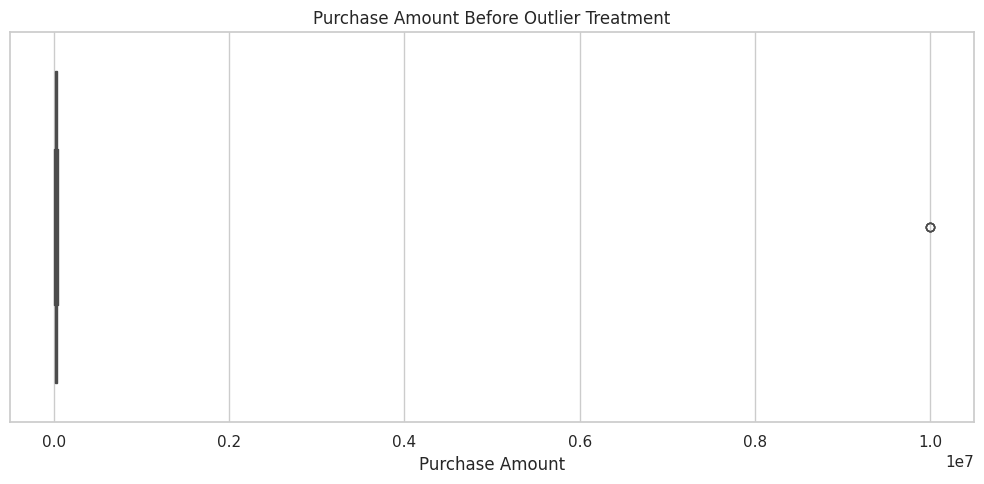

In [52]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=clean_df["purchase_amount"]
)

plt.title("Purchase Amount Before Outlier Treatment")
plt.xlabel("Purchase Amount")
plt.tight_layout()

plt.show()

### Outlier Observation

The box plot is used to visualise unusually low or high purchase values.

Potential outliers should not automatically be deleted, because some extreme values may represent legitimate high-value customers or transactions.

## 17. Outlier Treatment

Purchase amount outliers are capped at the IQR boundaries rather than removed.

This preserves the number of customer records while reducing the influence of unusually extreme purchase values on later analysis.

In [53]:
clean_df["purchase_amount"] = clean_df["purchase_amount"].clip(
    lower=lower_bound,
    upper=upper_bound
)

print(clean_df["purchase_amount"].describe())

count     9163.000000
mean     24695.701844
std      13630.812225
min          0.000000
25%      13894.500000
50%      24340.000000
75%      35654.000000
max      68293.250000
Name: purchase_amount, dtype: float64


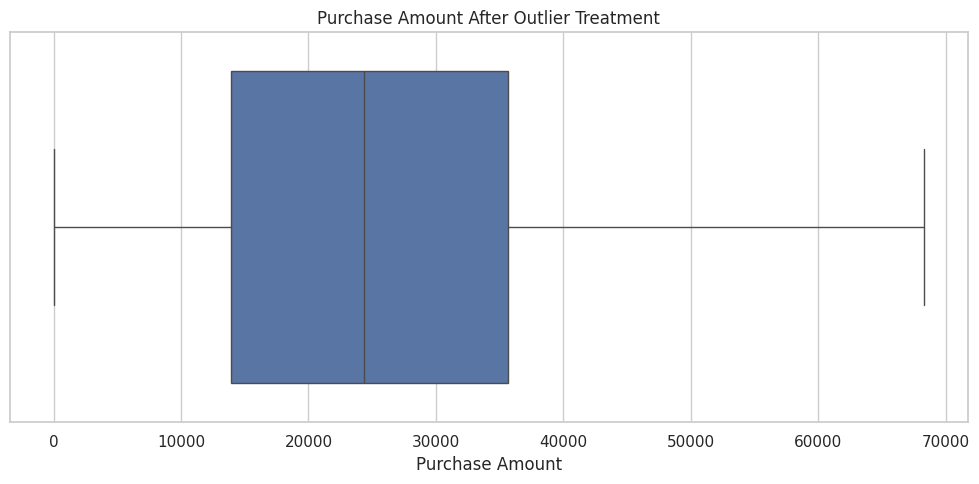

In [54]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=clean_df["purchase_amount"]
)

plt.title("Purchase Amount After Outlier Treatment")
plt.xlabel("Purchase Amount")
plt.tight_layout()

plt.show()

### Outlier Treatment Decision

IQR-based capping was chosen instead of deleting outlier rows.

This approach reduces the statistical influence of extreme values while retaining the underlying customer records.

## 18. Final Data Type Correction

After cleaning, all columns are checked to ensure that each variable uses an appropriate data type.

In [55]:
clean_df.dtypes

,0
customer_id,object
name,object
gender,object
age,int64
city,string[python]
signup_date,datetime64[ns]
last_purchase_date,datetime64[ns]
purchase_amount,float64
feedback_score,float64
email,object


In [56]:
clean_df["customer_id"] = clean_df["customer_id"].astype("string")
clean_df["gender"] = clean_df["gender"].astype("category")
clean_df["city"] = clean_df["city"].astype("category")
clean_df["country"] = clean_df["country"].astype("category")

clean_df["age"] = clean_df["age"].astype(int)

clean_df["purchase_amount"] = clean_df["purchase_amount"].astype(float)
clean_df["feedback_score"] = clean_df["feedback_score"].astype(float)

print(clean_df.dtypes)

customer_id           string[python]
name                          object
gender                      category
age                            int64
city                        category
signup_date           datetime64[ns]
last_purchase_date    datetime64[ns]
purchase_amount              float64
feedback_score               float64
email                         object
phone_number                   int64
country                     category
dtype: object


## 19. Final Missing Value Audit

A final missing-value check is performed after all cleaning operations to confirm whether any unresolved incomplete data remains.

In [57]:
final_missing_report = pd.DataFrame({
    "Missing Values": clean_df.isnull().sum(),
    "Missing Percentage": (
        clean_df.isnull().sum() / len(clean_df) * 100
    ).round(2)
})

final_missing_report

,Missing Values,Missing Percentage
customer_id,0,0.0
name,0,0.0
gender,0,0.0
age,0,0.0
city,0,0.0
signup_date,0,0.0
last_purchase_date,0,0.0
purchase_amount,0,0.0
feedback_score,0,0.0
email,0,0.0


In [58]:
print(
    "Total missing values remaining:",
    clean_df.isnull().sum().sum()
)

Total missing values remaining: 0


In [59]:
print("Exact duplicate rows remaining:",
      clean_df.duplicated().sum())

Exact duplicate rows remaining: 160


## 20. Before vs After Data Quality Comparison

The final stage compares the quality of the raw dataset with the cleaned dataset.

This demonstrates the effect of the cleaning process on missing values, duplicate rows, row count and data-type consistency.

In [60]:
after_rows = len(clean_df)
after_duplicates = clean_df.duplicated().sum()
after_missing = clean_df.isnull().sum().sum()

before_after_summary = pd.DataFrame({
    "Metric": [
        "Row Count",
        "Missing Values",
        "Duplicate Rows"
    ],
    "Before Cleaning": [
        before_rows,
        before_missing,
        before_duplicates
    ],
    "After Cleaning": [
        after_rows,
        after_missing,
        after_duplicates
    ]
})

before_after_summary

,Metric,Before Cleaning,After Cleaning
0,Row Count,10200,9163
1,Missing Values,7804,0
2,Duplicate Rows,15,160


In [61]:
dtype_comparison = pd.DataFrame({
    "Before Cleaning": df.dtypes.astype(str),
    "After Cleaning": clean_df.dtypes.astype(str)
})

dtype_comparison

,Before Cleaning,After Cleaning
Age,object,NaN
City,object,NaN
Country,object,NaN
Customer_ID,object,NaN
Email,object,NaN
Feedback_Score,float64,NaN
Gender,object,NaN
Last_Purchase_Date,object,NaN
Name,object,NaN
Phone_Number,int64,NaN


## 21. Final Cleaned Dataset

In [62]:
clean_df.head(10)

,customer_id,name,gender,age,city,signup_date,last_purchase_date,purchase_amount,feedback_score,email,phone_number,country
0,CUST4371,Paul Wilson,Male,52,Kolkata,2025-06-26,2025-05-17,26944.0,1.0,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,Male,51,Mumbai,2021-02-17,2025-07-22,44152.0,2.0,owensanthony@example.com,1080761560,India
2,CUST3754,Brittney Martinez,Female,62,Hyderabad,2023-11-05,2024-12-08,31745.0,2.0,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,Female,40,Hyderabad,2022-03-13,2025-10-02,39674.0,1.0,berrynancy@example.org,8228064204,India
4,CUST5683,Matthew Carroll,Female,41,Chennai,2024-04-05,2024-12-15,24340.0,3.0,denise84@example.org,2665569480,India
5,CUST1516,William Day,Female,43,Kolkata,2021-05-02,2025-06-09,27663.0,3.0,richard34@example.net,9463089646,India
6,CUST3651,Laura Vincent,Male,18,Bangalore,2024-06-16,2025-04-25,24340.0,3.0,ymiranda@example.net,6917110630,India
7,CUST10438,Timothy Dunlap,Female,43,Hyderabad,2025-03-16,2025-04-25,18355.0,3.0,christopheranderson@example.net,9981404428,India
8,CUST5189,Sabrina Miller,Female,40,Chennai,2025-07-07,2024-10-30,24340.0,3.0,shepardcolton@example.net,6233441825,India
9,CUST8237,Mr. Thomas Garcia,Female,26,Mumbai,2025-05-24,2024-10-15,28206.0,3.0,heidimartinez@example.org,1225343854,India


In [63]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9163 entries, 0 to 10199
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_id         9163 non-null   string        
 1   name                9163 non-null   object        
 2   gender              9163 non-null   category      
 3   age                 9163 non-null   int64         
 4   city                9163 non-null   category      
 5   signup_date         9163 non-null   datetime64[ns]
 6   last_purchase_date  9163 non-null   datetime64[ns]
 7   purchase_amount     9163 non-null   float64       
 8   feedback_score      9163 non-null   float64       
 9   email               9163 non-null   object        
 10  phone_number        9163 non-null   int64         
 11  country             9163 non-null   category      
dtypes: category(3), datetime64[ns](2), float64(2), int64(2), object(2), string(1)
memory usage: 743.2+ KB


In [64]:
clean_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,9163,9000,CUST6647,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,9163,8482,Jennifer Smith,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,9163,2,Female,5028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,9163.0,NaN,NaN,NaN,43.45149,18.0,32.0,43.0,55.0,69.0,14.168218
city,9163,6,Mumbai,2301,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,9163,NaN,NaN,NaN,2023-04-12 18:25:06.318891008,2020-10-08 00:00:00,2022-01-18 00:00:00,2023-04-05 00:00:00,2024-07-13 00:00:00,2025-10-08 00:00:00,NaN
last_purchase_date,9163,NaN,NaN,NaN,2025-04-08 05:43:51.147004416,2024-10-08 00:00:00,2025-01-17 00:00:00,2025-04-08 00:00:00,2025-06-28 00:00:00,2025-10-08 00:00:00,NaN
purchase_amount,9163.0,NaN,NaN,NaN,24695.701844,0.0,13894.5,24340.0,35654.0,68293.25,13630.812225
feedback_score,9163.0,NaN,NaN,NaN,2.993452,1.0,3.0,3.0,3.0,5.0,0.942323
email,9163,8829,wwilliams@example.net,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 22. Exporting the Cleaned Dataset

The final cleaned dataframe is exported as a new CSV file so that it can be used for future analysis without repeating the cleaning process.

In [65]:
output_file = "cleaned_customer_sales_data.csv"

clean_df.to_csv(
    output_file,
    index=False
)

print(f"Cleaned dataset saved successfully as: {output_file}")

Cleaned dataset saved successfully as: cleaned_customer_sales_data.csv


In [66]:
from google.colab import files

files.download("cleaned_customer_sales_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 23. Conclusion

The raw customer sales dataset was systematically transformed into a clean and analysis-ready dataset.

The cleaning process included:

- Exact duplicate removal
- Column-name standardisation
- Gender standardisation
- City and country standardisation
- Age extraction and validation
- Missing-value treatment
- Date conversion
- Invalid purchase amount treatment
- Feedback score validation
- Customer ID quality checks
- IQR-based outlier detection
- Outlier capping
- Data-type correction
- Final missing-value and duplicate audits
- Before-and-after data-quality comparison

The cleaned dataset was exported as `cleaned_customer_sales_data.csv`.

This process demonstrates how structured data cleaning improves consistency, reliability and readiness for future business analysis.